# Naive Bayes on MNIST Dataset
This notebook implements and compares three Naive Bayes classifiers — **GaussianNB**, **MultinomialNB**, and **BernoulliNB** — on the MNIST handwritten digit dataset.

### Objectives
- Load and preprocess the MNIST dataset
- Train each Naive Bayes model
- Evaluate their performance
- Visualize confusion matrices and reports

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB, MultinomialNB, BernoulliNB
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

## 1️⃣ Load and Prepare the Data

In [2]:
print('Loading MNIST dataset...')
mnist = fetch_openml('mnist_784', version=1)
X, y = mnist.data, mnist.target.astype(int)

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print(f'Training samples: {X_train.shape[0]}, Test samples: {X_test.shape[0]}')

Loading MNIST dataset...
Training samples: 56000, Test samples: 14000


## 2️⃣ Normalize Data for GaussianNB

In [3]:
X_train_scaled = X_train / 255.0
X_test_scaled = X_test / 255.0

## 3️⃣ Train Gaussian Naive Bayes

In [4]:
gnb = GaussianNB()
print('Training GaussianNB...')
gnb.fit(X_train_scaled, y_train)
y_pred_gnb = gnb.predict(X_test_scaled)
acc_gnb = accuracy_score(y_test, y_pred_gnb)
print(f'GaussianNB Accuracy: {acc_gnb:.4f}')

Training GaussianNB...
GaussianNB Accuracy: 0.5516


## 4️⃣ Train Multinomial Naive Bayes

In [5]:
mnb = MultinomialNB()
print('Training MultinomialNB...')
mnb.fit(X_train, y_train)
y_pred_mnb = mnb.predict(X_test)
acc_mnb = accuracy_score(y_test, y_pred_mnb)
print(f'MultinomialNB Accuracy: {acc_mnb:.4f}')

Training MultinomialNB...
MultinomialNB Accuracy: 0.8290


## 5️⃣ Train Bernoulli Naive Bayes

In [6]:
X_train_bin = (X_train > 0).astype(int)
X_test_bin = (X_test > 0).astype(int)

bnb = BernoulliNB()
print('Training BernoulliNB...')
bnb.fit(X_train_bin, y_train)
y_pred_bnb = bnb.predict(X_test_bin)
acc_bnb = accuracy_score(y_test, y_pred_bnb)
print(f'BernoulliNB Accuracy: {acc_bnb:.4f}')

Training BernoulliNB...
BernoulliNB Accuracy: 0.8349


## 6️⃣ Compare Model Accuracies

In [7]:
print('\nModel Performance Summary:')
print(f'GaussianNB  : {acc_gnb:.4f}')
print(f'MultinomialNB: {acc_mnb:.4f}')
print(f'BernoulliNB : {acc_bnb:.4f}')


Model Performance Summary:
GaussianNB  : 0.5516
MultinomialNB: 0.8290
BernoulliNB : 0.8349


## 7️⃣ Confusion Matrix for the Best Model


Best Model: BernoulliNB


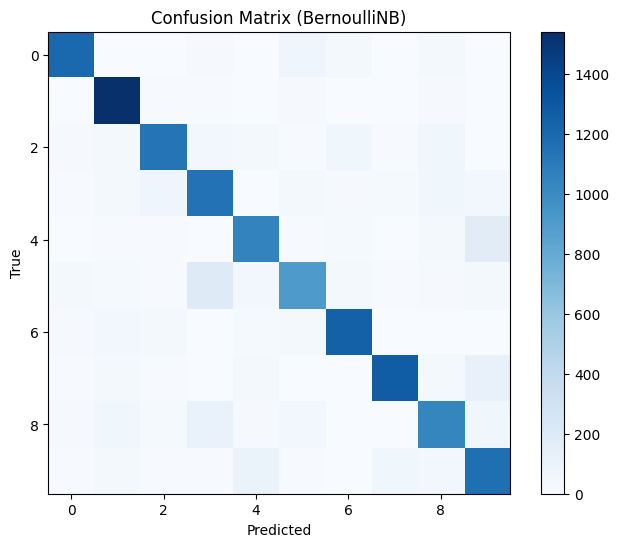

In [8]:
best_model_name = max({'GaussianNB': acc_gnb, 'MultinomialNB': acc_mnb, 'BernoulliNB': acc_bnb}, key=lambda k: {'GaussianNB': acc_gnb, 'MultinomialNB': acc_mnb, 'BernoulliNB': acc_bnb}[k])
print(f'\nBest Model: {best_model_name}')

if best_model_name == 'GaussianNB':
    best_pred, best_y = y_pred_gnb, y_test
elif best_model_name == 'MultinomialNB':
    best_pred, best_y = y_pred_mnb, y_test
else:
    best_pred, best_y = y_pred_bnb, y_test

cm = confusion_matrix(best_y, best_pred)
plt.figure(figsize=(8,6))
plt.imshow(cm, cmap='Blues')
plt.title(f'Confusion Matrix ({best_model_name})')
plt.xlabel('Predicted')
plt.ylabel('True')
plt.colorbar()
plt.show()

## 8️⃣ Classification Report for the Best Model

In [ ]:
print('Classification Report:')
print(classification_report(best_y, best_pred))